# Etap 7 — Wizualizacja danych i prezentacja wyników

**Cel:** poznanie metod i narzędzi wizualizacji danych oraz ich wykorzystanie do prezentacji wyników.
**Rezultat etapu:** przedstawienie wyników analizy, uczenia maszynowego i grupowania.

Narzędzia: biblioteki Python (**matplotlib**, **seaborn**) w tym notebooku oraz platforma **KNIME Analytics Platform** (dashboard, `knime/`).
Ten notebook: (1) odpowiada wykresami na 5 pytań analitycznych, (2) zestawia wyniki algorytmów, (3) eksportuje dane z dwóch źródeł do KNIME.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent))
from src.utils import *  # ścieżki, wczytywanie danych, styl wykresów

set_plot_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

In [2]:
cities = pd.read_csv(PROCESSED_DIR / "miasta_klastry.csv")
monthly = pd.read_csv(PROCESSED_DIR / "ceny_miesieczne.csv")
cost_long = pd.read_csv(PROCESSED_DIR / "koszty_zycia_2010_2024_clean.csv")
offers = pd.read_csv(PROCESSED_DIR / "oferty_klastry.csv")
models = pd.read_csv(PROCESSED_DIR / "wyniki_modeli.csv")
clusters = pd.read_csv(PROCESSED_DIR / "wyniki_grupowania.csv")
importance = pd.read_csv(PROCESSED_DIR / "waznosc_atrybutow.csv")
GROUP_COLORS = dict(zip(sorted(cities["grupa_miast"].unique()), sns.color_palette("Set2", 4)))
print(cities.shape, offers.shape)

(15, 41) (91292, 18)


## 7.1 Pytanie 1 — Dostępność dochodowa
*Ile miesięcznych pensji netto (lub lat oszczędzania przy 30% pensji) potrzeba na zakup mieszkania 50 m²?*

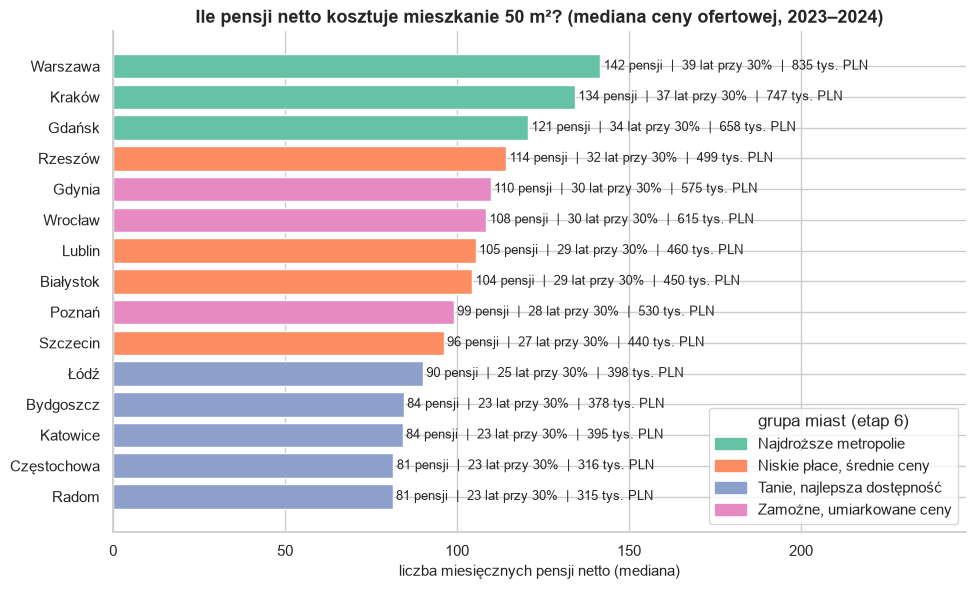

In [3]:
d = cities.sort_values("miesiace_pensji_50m2")
fig, ax = plt.subplots(figsize=(11, 6.5))
bars = ax.barh(d["miasto"], d["miesiace_pensji_50m2"], color=d["grupa_miast"].map(GROUP_COLORS))
for bar, (_, r) in zip(bars, d.iterrows()):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2,
            f"{r['miesiace_pensji_50m2']:.0f} pensji  |  {r['lata_oszczedzania_30proc']:.0f} lat przy 30%  |  {r['cena_50m2']/1000:,.0f} tys. PLN".replace(",", " "),
            va="center", fontsize=9)
ax.set_xlim(0, d["miesiace_pensji_50m2"].max() * 1.75)
ax.set_title("Ile pensji netto kosztuje mieszkanie 50 m²? (mediana ceny ofertowej, 2023–2024)")
ax.set_xlabel("liczba miesięcznych pensji netto (mediana)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in GROUP_COLORS.values()]
ax.legend(handles, GROUP_COLORS.keys(), loc="lower right", title="grupa miast (etap 6)")
save_fig(fig, "07_p1_dostepnosc_dochodowa")
plt.show()

## 7.2 Pytanie 2 — Zakup czy najem?
*Gdzie stosunek rocznego czynszu do ceny jest najkorzystniejszy dla inwestora, a gdzie bardziej opłaca się wynajmować?*

- **Rentowność brutto** = roczny czynsz / cena — im wyższa, tym lepiej dla inwestora.
- **Price-to-rent** (cena / roczny czynsz) — im wyższy, tym bardziej opłaca się *wynajmować* niż kupować.

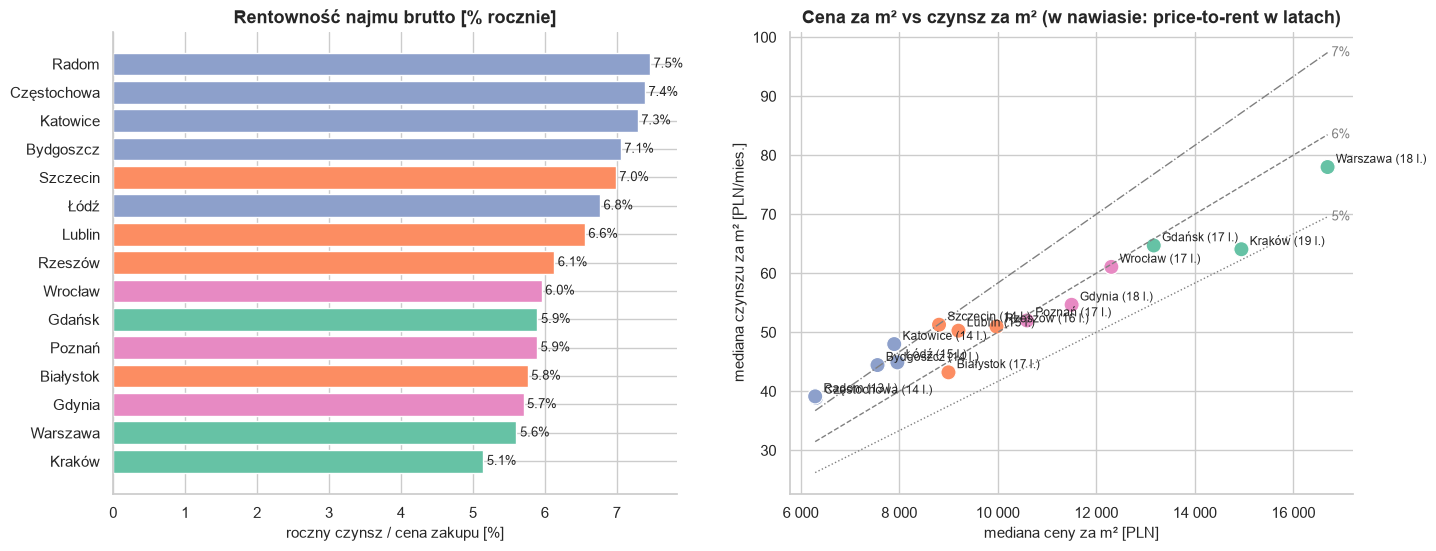

,mediana_cena_m2,mediana_czynsz_m2,rentownosc_brutto_proc,cena_do_czynszu_lata,czynsz_do_pensji_proc
miasto,,,,,
Radom,"6,294.60",39.10,7.50,13.40,50.50
Częstochowa,"6,313.30",38.90,7.40,13.50,50.20
Katowice,"7,899.00",48.00,7.30,13.70,51.10
Bydgoszcz,"7,559.60",44.40,7.10,14.20,49.70
Szczecin,"8,808.80",51.30,7.00,14.30,55.90
Łódź,"7,963.00",44.90,6.80,14.80,50.80
Lublin,"9,202.50",50.30,6.60,15.30,57.60
Rzeszów,"9,975.20",51.00,6.10,16.30,58.40
Wrocław,"12,306.40",61.10,6.00,16.80,53.80


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
d = cities.sort_values("rentownosc_brutto_proc")
axes[0].barh(d["miasto"], d["rentownosc_brutto_proc"], color=d["grupa_miast"].map(GROUP_COLORS))
for i, v in enumerate(d["rentownosc_brutto_proc"]):
    axes[0].text(v + 0.05, i, f"{v:.1f}%", va="center", fontsize=9)
axes[0].set_title("Rentowność najmu brutto [% rocznie]")
axes[0].set_xlabel("roczny czynsz / cena zakupu [%]")

sns.scatterplot(data=cities, x="mediana_cena_m2", y="mediana_czynsz_m2", hue="grupa_miast", palette=GROUP_COLORS,
                s=120, ax=axes[1], legend=False)
for _, r in cities.iterrows():
    axes[1].annotate(f"{r['miasto']} ({r['cena_do_czynszu_lata']:.0f} l.)", (r["mediana_cena_m2"], r["mediana_czynsz_m2"]),
                     xytext=(6, 3), textcoords="offset points", fontsize=8.5)
x = np.linspace(cities["mediana_cena_m2"].min(), cities["mediana_cena_m2"].max(), 50)
for yld, ls in [(5, ":"), (6, "--"), (7, "-.")]:
    axes[1].plot(x, x * yld / 100 / 12, color="gray", ls=ls, lw=1)
    axes[1].text(x[-1], x[-1] * yld / 100 / 12, f" {yld}%", color="gray", va="center", fontsize=9)
axes[1].set_title("Cena za m² vs czynsz za m² (w nawiasie: price-to-rent w latach)")
axes[1].set_xlabel("mediana ceny za m² [PLN]")
axes[1].set_ylabel("mediana czynszu za m² [PLN/mies.]")
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(thousands))
save_fig(fig, "07_p2_zakup_vs_najem")
plt.show()
cities.set_index("miasto")[["mediana_cena_m2", "mediana_czynsz_m2", "rentownosc_brutto_proc", "cena_do_czynszu_lata",
                            "czynsz_do_pensji_proc"]].sort_values("rentownosc_brutto_proc", ascending=False).round(1)

## 7.3 Pytanie 3 — Czynniki mikrolokalizacyjne
*Jak odległość od centrum, rok budowy i infrastruktura w promieniu 500 m wpływają na cenę m²?*

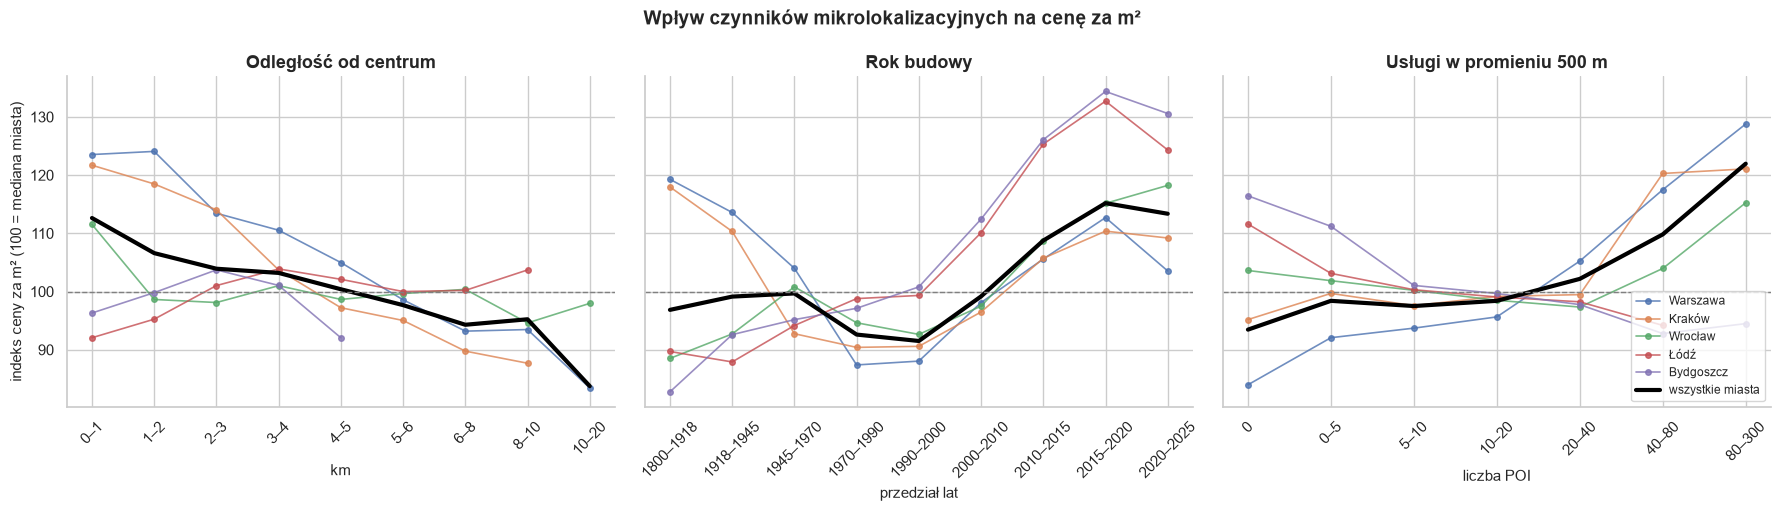

In [5]:
offers["odl_bin"] = pd.cut(offers["centreDistance"], [0, 1, 2, 3, 4, 5, 6, 8, 10, 20])
offers["poi_bin"] = pd.cut(offers["poiCount"], [-1, 0, 5, 10, 20, 40, 80, 300])
offers["rok_bin"] = pd.cut(offers["buildYear"], [1800, 1918, 1945, 1970, 1990, 2000, 2010, 2015, 2020, 2025])

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), sharey=True)
for ax, col, title, xlabel in [(axes[0], "odl_bin", "Odległość od centrum", "km"),
                               (axes[1], "rok_bin", "Rok budowy", "przedział lat"),
                               (axes[2], "poi_bin", "Usługi w promieniu 500 m", "liczba POI")]:
    g = offers.groupby([col, "city_label"], observed=True)["price_index_city"].median().unstack()
    for city in ["Warszawa", "Kraków", "Wrocław", "Łódź", "Bydgoszcz"]:
        ax.plot(range(len(g)), g[city], marker="o", ms=4, lw=1.2, alpha=0.8, label=city)
    overall = offers.groupby(col, observed=True)["price_index_city"].median()
    ax.plot(range(len(overall)), overall.values, color="black", lw=3, label="wszystkie miasta")
    ticks = [str(i).replace("(", "").replace("]", "").replace(", ", "–") for i in overall.index]
    ticks = ["0" if t == "-1–0" else t for t in ticks]
    ax.set_xticks(range(len(overall)), ticks, rotation=45)
    ax.axhline(100, color="gray", ls="--", lw=1)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
axes[0].set_ylabel("indeks ceny za m² (100 = mediana miasta)")
axes[2].legend(fontsize=8.5, loc="lower right")
fig.suptitle("Wpływ czynników mikrolokalizacyjnych na cenę za m²", fontweight="bold", fontsize=14)
fig.tight_layout()
save_fig(fig, "07_p3_mikrolokalizacja")
plt.show()

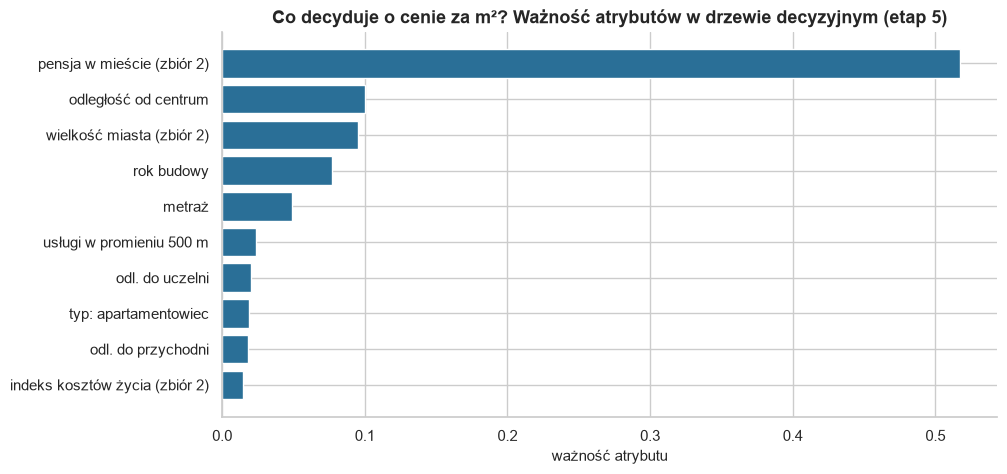

In [6]:
nice = {"median_salary_net_pln": "pensja w mieście (zbiór 2)", "centreDistance": "odległość od centrum",
        "population_approx": "wielkość miasta (zbiór 2)", "buildYear": "rok budowy", "squareMeters": "metraż",
        "poiCount": "usługi w promieniu 500 m", "collegeDistance": "odl. do uczelni", "type_apartmentBuilding": "typ: apartamentowiec",
        "clinicDistance": "odl. do przychodni", "cost_of_living_index": "indeks kosztów życia (zbiór 2)"}
top = importance.head(10).assign(atrybut=lambda d: d["atrybut"].map(nice).fillna(d["atrybut"]))
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top["atrybut"][::-1], top["waznosc"][::-1], color="#2a6f97")
ax.set_title("Co decyduje o cenie za m²? Ważność atrybutów w drzewie decyzyjnym (etap 5)")
ax.set_xlabel("ważność atrybutu")
save_fig(fig, "07_p3_waznosc_atrybutow")
plt.show()

## 7.4 Pytanie 4 — Dochód dyspozycyjny
*Jak zmienia się czas oszczędzania na wkład własny (20% ceny 50 m²), gdy od pensji odejmiemy podstawowe koszty życia?*

- **Scenariusz A:** odkładamy 30% pensji netto (prosty wskaźnik, bez uwzględnienia kosztów),
- **Scenariusz B:** od pensji odejmujemy koszty życia bez mieszkania (zbiór 2), a odkładamy połowę tego, co zostanie.

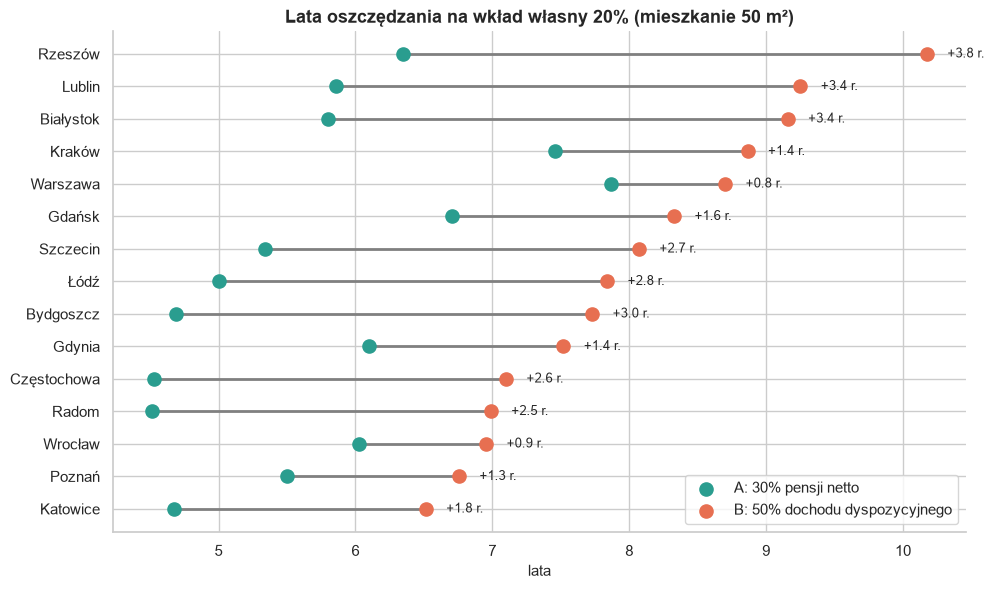

,median_salary_net_pln,koszty_bez_mieszkania,dochod_dyspozycyjny,lata_wklad20_30proc_pensji,lata_wklad20_50proc_dysp
miasto,,,,,
Katowice,4693,2672,2021,4.70,6.50
Poznań,5348,2735,2613,5.50,6.80
Wrocław,5675,2726,2949,6.00,7.00
Radom,3874,2373,1501,4.50,7.00
Częstochowa,3874,2392,1482,4.50,7.10
Gdynia,5239,2690,2549,6.10,7.50
Bydgoszcz,4475,2845,1630,4.70,7.70
Łódź,4420,2727,1693,5.00,7.80
Szczecin,4584,2765,1819,5.30,8.10


In [7]:
d = cities.sort_values("lata_wklad20_50proc_dysp")
fig, ax = plt.subplots(figsize=(11, 6.5))
y = np.arange(len(d))
ax.hlines(y, d["lata_wklad20_30proc_pensji"], d["lata_wklad20_50proc_dysp"], color="gray", lw=2)
ax.scatter(d["lata_wklad20_30proc_pensji"], y, s=90, color="#2a9d8f", label="A: 30% pensji netto", zorder=3)
ax.scatter(d["lata_wklad20_50proc_dysp"], y, s=90, color="#e76f51", label="B: 50% dochodu dyspozycyjnego", zorder=3)
for yi, (_, r) in zip(y, d.iterrows()):
    ax.text(max(r["lata_wklad20_30proc_pensji"], r["lata_wklad20_50proc_dysp"]) + 0.15, yi,
            f"+{r['lata_wklad20_50proc_dysp'] - r['lata_wklad20_30proc_pensji']:.1f} r." if r['lata_wklad20_50proc_dysp'] > r['lata_wklad20_30proc_pensji']
            else f"{r['lata_wklad20_50proc_dysp'] - r['lata_wklad20_30proc_pensji']:.1f} r.", va="center", fontsize=9)
ax.set_yticks(y, d["miasto"])
ax.set_title("Lata oszczędzania na wkład własny 20% (mieszkanie 50 m²)")
ax.set_xlabel("lata")
ax.legend(loc="lower right")
save_fig(fig, "07_p4_wklad_wlasny")
plt.show()
cities.set_index("miasto")[["median_salary_net_pln", "koszty_bez_mieszkania", "dochod_dyspozycyjny",
                            "lata_wklad20_30proc_pensji", "lata_wklad20_50proc_dysp"]].sort_values("lata_wklad20_50proc_dysp").round(1)

## 7.5 Pytanie 5 — Zróżnicowanie regionalne
*Czy miasta o najwyższych zarobkach są względnie bardziej czy mniej dostępne niż ośrodki regionalne?*

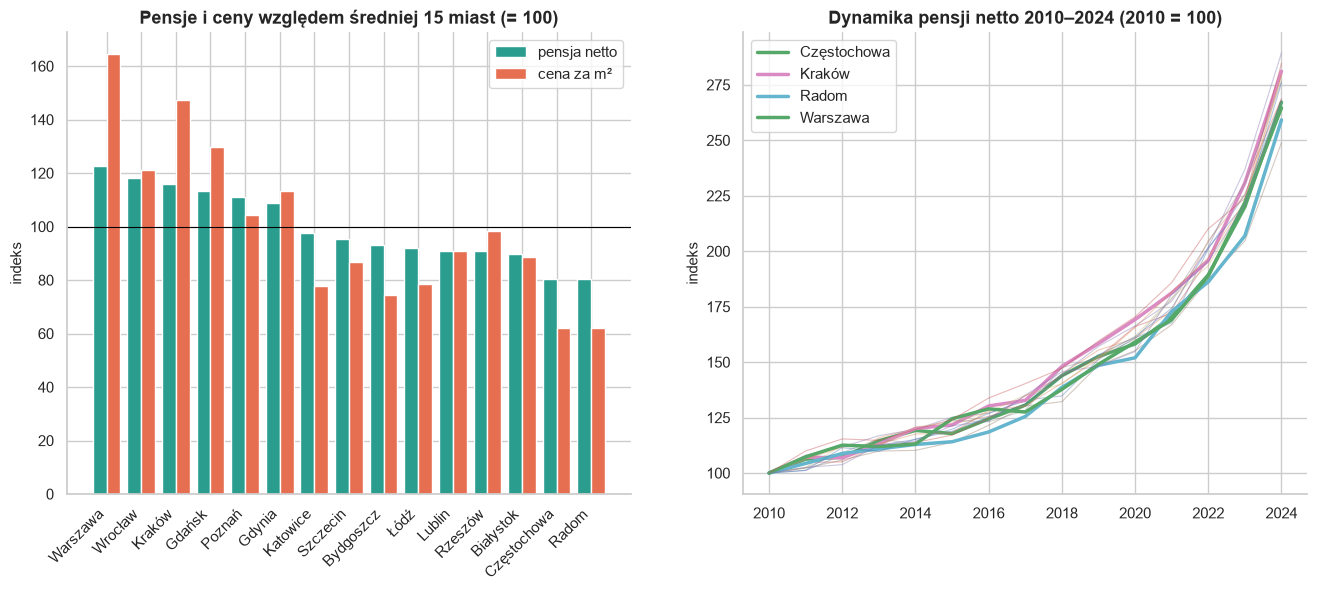

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
d = cities.sort_values("median_salary_net_pln", ascending=False)
x = np.arange(len(d))
axes[0].bar(x - 0.2, d["median_salary_net_pln"] / d["median_salary_net_pln"].mean() * 100, 0.4, label="pensja netto", color="#2a9d8f")
axes[0].bar(x + 0.2, d["mediana_cena_m2"] / d["mediana_cena_m2"].mean() * 100, 0.4, label="cena za m²", color="#e76f51")
axes[0].axhline(100, color="black", lw=0.8)
axes[0].set_xticks(x, d["miasto"], rotation=45, ha="right")
axes[0].set_title("Pensje i ceny względem średniej 15 miast (= 100)")
axes[0].set_ylabel("indeks")
axes[0].legend()

pivot = cost_long[cost_long["city_norm"].isin(CITY_LABELS)].pivot_table(index="year", columns="city", values="median_salary_net_pln")
pivot = pivot / pivot.loc[2010] * 100
for city in pivot.columns:
    hl = city in ["Warszawa", "Kraków", "Radom", "Częstochowa"]
    axes[1].plot(pivot.index, pivot[city], lw=2.5 if hl else 0.8, alpha=1 if hl else 0.4, label=city if hl else None)
axes[1].set_title("Dynamika pensji netto 2010–2024 (2010 = 100)")
axes[1].set_ylabel("indeks")
axes[1].legend()
save_fig(fig, "07_p5_zroznicowanie_regionalne")
plt.show()

## 7.6 Dynamika cen w czasie (dane czasowe)

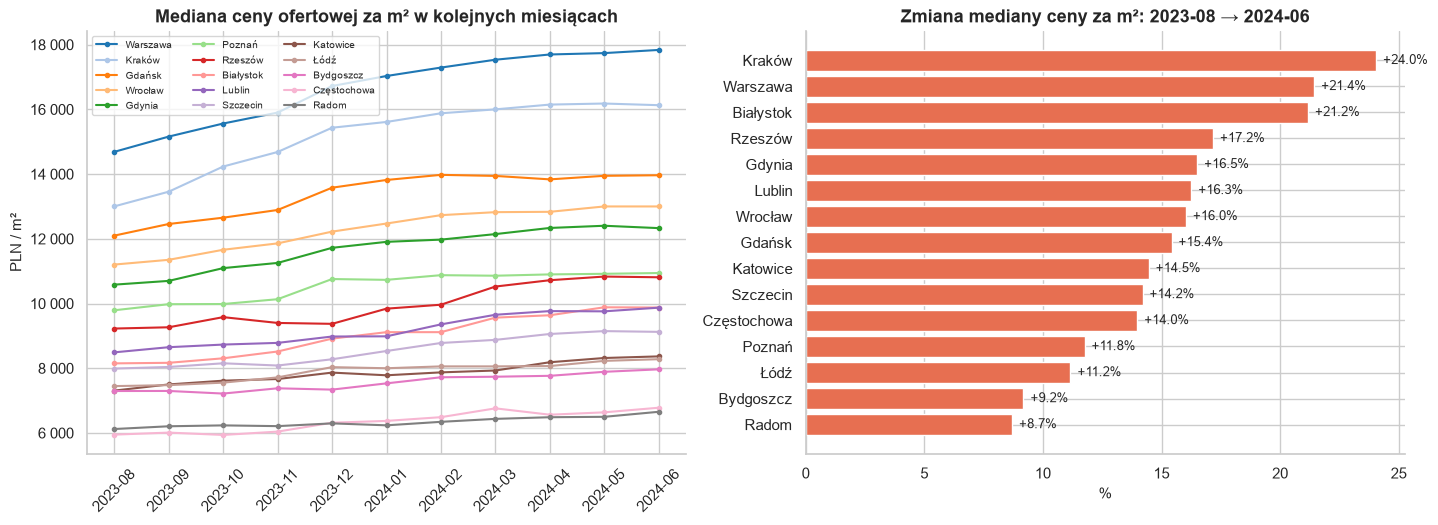

In [9]:
p = monthly.pivot_table(index="period", columns="city_label", values="mediana_cena_m2")
p_idx = p / p.iloc[0] * 100
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
palette = sns.color_palette("tab20", len(p.columns))
last = p.iloc[-1].sort_values(ascending=False)
for color, city in zip(palette, last.index):  # legenda w kolejności cen
    axes[0].plot(p.index, p[city], marker="o", ms=3, label=city, color=color)
axes[0].set_title("Mediana ceny ofertowej za m² w kolejnych miesiącach")
axes[0].set_ylabel("PLN / m²")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(thousands))
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend(fontsize=7.5, ncol=3)
change = (p_idx.iloc[-1] - 100).sort_values()
axes[1].barh(change.index, change.values, color=["#e76f51" if v > 0 else "#2a9d8f" for v in change.values])
for i, v in enumerate(change.values):
    axes[1].text(v + 0.3, i, f"{v:+.1f}%", va="center", fontsize=9)
axes[1].set_title(f"Zmiana mediany ceny za m²: {p.index[0]} → {p.index[-1]}")
axes[1].set_xlabel("%")
save_fig(fig, "07_dynamika_cen")
plt.show()

## 7.7 Zestawienie wyników algorytmów uczenia maszynowego i grupowania

In [10]:
summary = pd.concat([
    models.assign(rodzaj="nadzorowane", miara=lambda d: np.where(d["R²"].notna(),
        "R² = " + d["R²"].round(3).astype(str) + "; MAE = " + d["MAE [PLN/m²]"].round(0).astype(int, errors="ignore").astype(str) + " PLN/m²",
        "accuracy = " + d["accuracy"].round(3).astype(str) + "; F1 = " + d["F1 makro"].round(3).astype(str)))
          [["rodzaj", "zadanie", "model", "miara"]],
    clusters.assign(rodzaj="nienadzorowane", zadanie="grupowanie: " + clusters["poziom"],
                    model=clusters["metoda"] + " (k = " + clusters["k"].astype(str) + ")",
                    miara="silhouette = " + clusters["silhouette"].round(3).astype(str) + "; ARI = " + clusters["ARI vs druga metoda"].round(2).astype(str))
            [["rodzaj", "zadanie", "model", "miara"]],
], ignore_index=True)
summary.to_csv(PROCESSED_DIR / "zestawienie_wynikow.csv", index=False)
summary

,rodzaj,zadanie,model,miara
0,nadzorowane,regresja: cena za m²,bazowy (mediana),R² = -0.007; MAE = 3787.0 PLN/m²
1,nadzorowane,regresja: cena za m²,regresja liniowa,R² = 0.653; MAE = 2125.0 PLN/m²
2,nadzorowane,regresja: cena za m²,drzewo decyzyjne (głęb. 15),R² = 0.784; MAE = 1553.0 PLN/m²
3,nadzorowane,regresja: cena za m²,las losowy (porównawczo),R² = 0.858; MAE = 1244.0 PLN/m²
4,nadzorowane,klasyfikacja: segment cenowy,bazowy (najczęstsza klasa),accuracy = 0.332; F1 = 0.166
5,nadzorowane,klasyfikacja: segment cenowy,drzewo decyzyjne (głęb. 15),accuracy = 0.623; F1 = 0.625
6,nienadzorowane,grupowanie: miasta (15),K-means (k = 4),silhouette = 0.362; ARI = 0.78
7,nienadzorowane,grupowanie: miasta (15),hierarchiczne (Ward) (k = 4),silhouette = 0.355; ARI = 0.78
8,nienadzorowane,grupowanie: oferty (próbka 10 tys.),K-means (k = 4),silhouette = 0.177; ARI = 0.3
9,nienadzorowane,grupowanie: oferty (próbka 10 tys.),hierarchiczne (Ward) (k = 4),silhouette = 0.126; ARI = 0.3


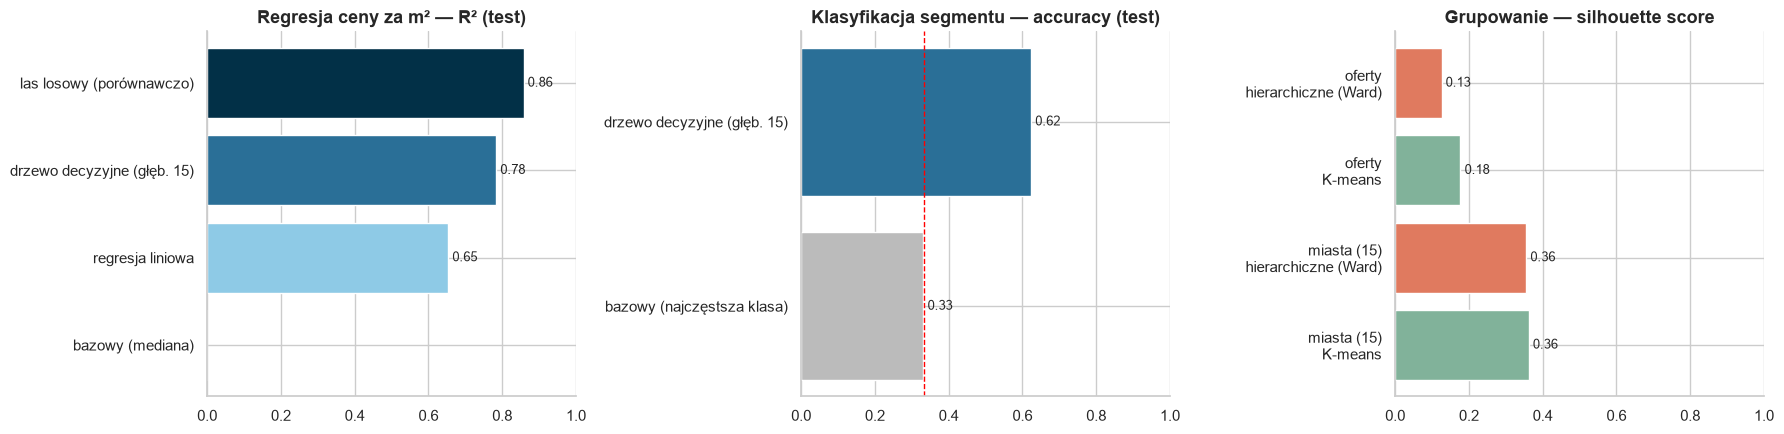

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
reg = models[models["R²"].notna()]
axes[0].barh(reg["model"], reg["R²"], color=["#bbb", "#8ecae6", "#2a6f97", "#023047"])
axes[0].set_title("Regresja ceny za m² — R² (test)")
axes[0].set_xlim(0, 1)
clf = models[models["accuracy"].notna()]
axes[1].barh(clf["model"], clf["accuracy"], color=["#bbb", "#2a6f97"])
axes[1].axvline(1 / 3, color="red", ls="--", lw=1)
axes[1].set_title("Klasyfikacja segmentu — accuracy (test)")
axes[1].set_xlim(0, 1)
lab = clusters["poziom"].str.replace(" (próbka 10 tys.)", "") + "\n" + clusters["metoda"]
axes[2].barh(lab, clusters["silhouette"], color=["#81b29a", "#e07a5f"] * 2)
axes[2].set_title("Grupowanie — silhouette score")
axes[2].set_xlim(0, 1)
for ax in axes:
    for c in ax.containers:
        ax.bar_label(c, fmt="%.2f", padding=3, fontsize=9)
fig.tight_layout()
save_fig(fig, "07_zestawienie_wynikow")
plt.show()

## 7.8 Eksport danych do KNIME Analytics Platform

Wymaganie: *import danych z minimum dwóch różnych źródeł lub zbioru powstałego z ich połączenia*. Eksportujemy:

| Plik | Źródło | Format | Zawartość |
|---|---|---|---|
| `oferty_segmenty.csv` | zbiór 1 (oferty) + wyniki ML/grupowania | **CSV** | próbka 20 tys. ofert: cechy, cena, segment K-means, PC1/PC2 |
| `koszty_zycia_miasta.xlsx` | zbiór 2 (koszty życia, GUS/Numbeo) | **Excel** | 15 miast: płace, koszty życia + arkusz z szeregiem 2010–2024 |
| `miasta_wskazniki.csv` | połączenie zbiorów 1 + 2 | CSV | wskaźniki dostępności + grupa miast |
| `ceny_miesieczne.csv` | zbiór 1 | CSV | szereg czasowy median cen |
| `predykcje_test.csv` | wynik drzewa decyzyjnego | CSV | ceny rzeczywiste vs przewidywane (próbka) |
| `zestawienie_wynikow.csv` | wyniki etapów 5–6 | CSV | metryki modeli i grupowania |

In [12]:
knime_data = KNIME_DIR / "data"
knime_data.mkdir(parents=True, exist_ok=True)

offers_k = offers.drop(columns=["odl_bin", "poi_bin", "rok_bin"]).sample(20000, random_state=RANDOM_STATE)
offers_k.to_csv(knime_data / "oferty_segmenty.csv", index=False)

cost24 = pd.read_csv(PROCESSED_DIR / "koszty_zycia_2024_clean.csv")
cost24_big = cost24[cost24["city_norm"].isin(CITY_LABELS)].drop_duplicates("city_norm")
long_big = cost_long[cost_long["city_norm"].isin(CITY_LABELS)]
with pd.ExcelWriter(knime_data / "koszty_zycia_miasta.xlsx") as xw:
    cost24_big.to_excel(xw, sheet_name="koszty_2024", index=False)
    long_big.to_excel(xw, sheet_name="szereg_2010_2024", index=False)

city_cols = ["city_key", "miasto", "voivodeship", "grupa_miast", "mediana_cena_m2", "mediana_czynsz_m2", "cena_50m2",
             "median_salary_net_pln", "miesiace_pensji_50m2", "lata_oszczedzania_30proc", "dochod_dyspozycyjny",
             "lata_wklad20_30proc_pensji", "lata_wklad20_50proc_dysp", "rentownosc_brutto_proc", "cena_do_czynszu_lata",
             "czynsz_do_pensji_proc", "zmiana_ceny_m2_2023_08_2024_06_proc", "liczba_ofert_sprzedaz", "liczba_ofert_najem"]
cities[city_cols].round(2).to_csv(knime_data / "miasta_wskazniki.csv", index=False)
monthly.to_csv(knime_data / "ceny_miesieczne.csv", index=False)
pd.read_csv(PROCESSED_DIR / "predykcje_test.csv").sample(5000, random_state=RANDOM_STATE).to_csv(knime_data / "predykcje_test.csv", index=False)
summary.to_csv(knime_data / "zestawienie_wynikow.csv", index=False)

for f in sorted(knime_data.iterdir()):
    print(f"{f.name:30s} {f.stat().st_size / 1024:8.0f} KB")

ceny_miesieczne.csv                  10 KB
koszty_zycia_miasta.xlsx             34 KB
miasta_wskazniki.csv                  3 KB
oferty_segmenty.csv                3687 KB
predykcje_test.csv                  640 KB
zestawienie_wynikow.csv               1 KB


## 7.9 Wnioski końcowe — odpowiedzi na pytania analityczne

**1. Dostępność dochodowa.** Mieszkanie 50 m² kosztuje od **~81 pensji netto** (Radom, Częstochowa; ~23 lata oszczędzania 30% pensji)
do **~142 pensji** w Warszawie (~39 lat). Najtrudniej jest w Warszawie, Krakowie i Gdańsku, najłatwiej w Radomiu, Częstochowie, Katowicach i Bydgoszczy.

**2. Zakup vs najem.** Najwyższa rentowność najmu brutto jest w miastach tanich: **Radom (7,5%), Częstochowa (7,4%), Katowice (7,3%)** — tam zakup pod wynajem jest najkorzystniejszy dla inwestora.
Najniższa w **Krakowie (5,1%) i Warszawie (5,6%)** — price-to-rent ~18–19 lat; tam z perspektywy mieszkańca relatywnie bardziej opłaca się **wynajmować**.
Jednocześnie czynsz za 50 m² pochłania od ~49% (Poznań, Bydgoszcz) do **66% mediany pensji netto** (Warszawa) — najem dla singla jest obciążeniem wszędzie.

**3. Czynniki mikrolokalizacyjne.** W dużych miastach cena spada wraz z odległością od centrum (Warszawa, Kraków: ok. +22% w ścisłym centrum, −10% i więcej na obrzeżach)
i rośnie z liczbą usług w promieniu 500 m. W mniejszych miastach decyduje **rok budowy** — nowe budownictwo (2015–2020) jest tam o 25–35% droższe od mediany, a stare kamienice tańsze;
w Warszawie i Krakowie przeciwnie: przedwojenne kamienice (w centrum) mają premię. Drzewo decyzyjne potwierdza: po poziomie płac w mieście najważniejsze są odległość od centrum, wielkość miasta i rok budowy.

**4. Dochód dyspozycyjny.** Po odjęciu kosztów życia czas zbierania na wkład 20% **wydłuża się najbardziej w miastach o niskich płacach** — Rzeszów (6,3 → 10,2 roku), Lublin, Białystok (+3,4–3,9 roku),
a najmniej w Warszawie, Wrocławiu i Poznaniu (+0,8–1,3 roku), bo koszty życia są w Polsce podobne, a płace nie. W tym ujęciu najdostępniejsze stają się **Katowice, Poznań i Wrocław** (6,5–7 lat).

**5. Zróżnicowanie regionalne.** Miasta o najwyższych zarobkach są **względnie mniej dostępne** — ceny są w nich wyższe od średniej bardziej niż płace (Warszawa: pensja +23%, cena za m² +65% względem średniej 15 miast)
i przez ostatni rok rosły najszybciej (Kraków +24%, Warszawa +21%). Wyjątkiem są **Wrocław i Poznań** — wysokie płace przy umiarkowanych cenach.
Ośrodki regionalne nie są jednorodne: miasta *tanie* (Łódź, Katowice, Bydgoszcz) są naprawdę dostępne, a ściana wschodnia (Lublin, Rzeszów, Białystok) ma średnie ceny przy niskich płacach.

**Ograniczenia:** ceny ofertowe (nie transakcyjne), zbiór 2 częściowo modelowany (czynsze Numbeo odbiegają od ofert — dlatego czynsze liczono z ofert), mediana pensji miejskiej nie oddaje
dochodu gospodarstwa domowego (2 osoby), brak kosztu kredytu w scenariuszach oszczędzania.